In [1]:
import numpy as np

import sys
sys.path.insert(0,'../testproblems/tdarcy')
from NeuralOperator import NeuralOperator

In [2]:
#Standard libraries
import pytorch_lightning as pl
from tqdm.auto import tqdm, trange
from ipywidgets import IntProgress
import time
from torch import nn
from torch.nn import functional as F

#Personal ML stuff
import sys
sys.path.insert(0, '../../ml')
from logger import *
from trainer import train
from customlosses import *
from systemnets import *
from basisfunctions import *

#Test problem
from NeuralOperator import NeuralOperator
from DataModule import DataModule

#Training data
hparams = {}
hparams['N_samples_train'] = 10000
hparams['N_samples_val'] = 1000
hparams['variables'] = ['t','x','x']
hparams['d'] = len(hparams['variables'])
hparams['l_min'] = [0.5,0.5,0.5]
hparams['l_max'] = [1,1,1]
hparams['project_materialparameters'] = False
hparams['output_coefficients'] = False

#Training settings
hparams['dtype'] = torch.float32
hparams['precision'] = 32
hparams['used_device'] = 'cuda:2'
hparams['devices'] = [2]
hparams['solution_loss'] = weightedrelativeL2
hparams['matrix_loss'] = None #relativematrixnorm
hparams['metric'] = weightedrelativeL2
hparams['optimizer1'] = torch.optim.Adam
hparams['optimizer2'] = torch.optim.LBFGS
hparams['switch_threshold'] = None
hparams['learning_rate'] = 1e-3
hparams['batch_size'] = 100
hparams['epochs'] = 20000

#Bases
hparams['h'] = (2,10,10)
hparams['p'] = (1,3,3)
hparams['C'] = (0,2,2)
hparams['N'] = np.prod(hparams['h'])
hparams['test_bases'] = [BSplineBasis1D(h=hparams['h'][0], p=hparams['p'][0], C=hparams['C'][0]),
                         BSplineBasis1D(h=hparams['h'][1], p=hparams['p'][1], C=hparams['C'][1]),
                         BSplineBasis1D(h=hparams['h'][2], p=hparams['p'][2], C=hparams['C'][2])]
hparams['trial_bases'] = hparams['test_bases']
hparams['POD'] = False
hparams['Dt'] = 0.001

#Quadrature
hparams['quadrature'] = 'Gauss-Legendre'
hparams['n_elements'] = (1,3,3)
hparams['Q'] = (2,99,99)
hparams['quadrature_L'] = 'Gauss-Legendre'
hparams['n_elements_L'] = (1,3,3) #max(int((hparams['h'][0] - 1)/hparams['p']), 1)
hparams['Q_L'] = (2,99,99) #33*hparams['n_elements_L']

#System net'
hparams['modeltype'] = 'data NGO'
hparams['systemnet'] = CNN_3dto2d
hparams['N_w'] = 30000
hparams['skipconnections'] = False
# hparams['kernel_sizes'] = [2,2,5,10,10,5,2,2]
hparams['kernel_sizes'] = [(1,1,1),(1,1,1),(1,2,2),(2,5,5),(10,10),(5,5),(2,2),(2,2)]
hparams['bottleneck_size'] = 20
hparams['outputactivation'] = None

#Additional inductive bias
hparams['gamma_stabilization'] = 0
hparams['scaling_equivariance'] = False
hparams['massconservation'] = True
hparams['Neumannseries'] = False
hparams['Neumannseries_order'] = 0

In [3]:
model = NeuralOperator(hparams)

In [41]:
gamma = np.linspace(-200,200,20)
lambda_min = np.zeros(len(gamma))
lambda_max = np.zeros(len(gamma))
lambda_all = np.zeros((hparams['N'],len(gamma)))
theta_q = np.ones(hparams['Q']).flatten()[None,:]
F = model.compute_F_tensorized(theta_q)[0]

In [42]:
for i in range(len(gamma)):
    hparams['gamma_stabilization'] = gamma[i]
    model = NeuralOperator(hparams)
    F = model.compute_F_tensorized(theta_q)[0]
    lambda_min[i] = np.amin(np.real(np.linalg.eigvals(F)))
    lambda_max[i] = np.amax(np.real(np.linalg.eigvals(F)))
    lambda_all[:,i] = np.real(np.linalg.eigvals(F))

Text(0.5, 0, 'Stabilization parameter $C_\\mathrm{s}}$')

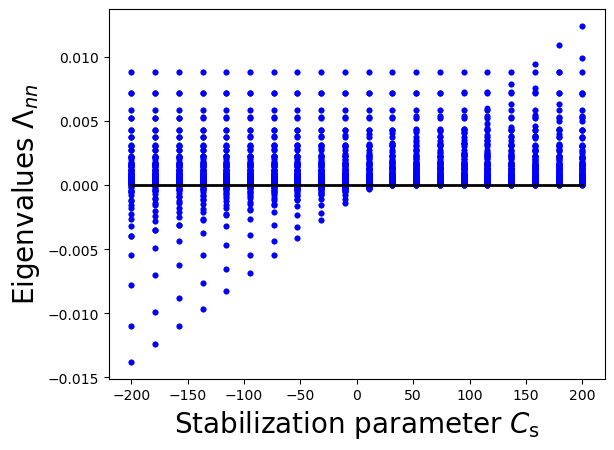

In [45]:
# plt.plot(gamma, lambda_min)
# plt.plot(gamma, lambda_max)
for i in range(hparams['N']):
    plt.scatter(gamma, lambda_all[i,:], color='blue', s=10)
plt.plot(gamma, np.zeros_like(gamma), color='black', linewidth=2)
# plt.yscale('log')
plt.ylabel(r'Eigenvalues $\Lambda_{nn}$', fontsize=20)
plt.xlabel(r'Stabilization parameter $C_\mathrm{s}}$'  , fontsize=20)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


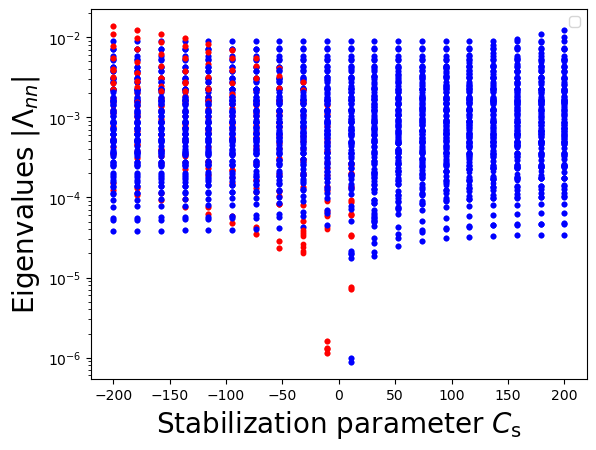

In [46]:
# plt.plot(gamma, lambda_min)
# plt.plot(gamma, lambda_max)
for i in range(hparams['N']):
    plt.scatter(gamma, lambda_all[i,:], color='blue', s=10)
    plt.scatter(gamma, -lambda_all[i,:], color='red', s=10)

plt.plot(gamma, np.zeros_like(gamma), color='black', linewidth=2)
plt.yscale('log')
plt.ylabel(r'Eigenvalues $|\Lambda_{nn}|$', fontsize=20)
plt.xlabel(r'Stabilization parameter $C_\mathrm{s}}$'  , fontsize=20)
plt.legend()